In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from IPython.display import display, clear_output
from IPython.display import display, clear_output

print("All libraries imported successfully!")

All libraries imported successfully!


In [18]:
file_path = "../data/Big12_Match_Data.xlsx"

df = pd.read_excel(
    file_path,
    sheet_name="Match Data")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [19]:
display(df.head())


,Game_ID,Date,Season,Game_Type,Team_A,Team_B,Score_A,Score_B,Score_Diff,Winner,Location,Team_A_Index,Team_B_Index,Include_In_Model
0,G001,2025-08-23,2025.0,Regular season,Kansas State Wildcats,Iowa State Cyclones,21.0,24.0,-3.0,Iowa State Cyclones,Neutral,10.0,8.0,1.0
1,G002,2025-09-12,2025.0,Regular season,Houston Cougars,Colorado Buffaloes,36.0,20.0,16.0,Houston Cougars,Home,7.0,6.0,1.0
2,G003,2025-09-20,2025.0,Regular season,Utah Utes,Texas Tech Red Raiders,10.0,34.0,-24.0,Texas Tech Red Raiders,Home,15.0,13.0,1.0
3,G004,2025-09-20,2025.0,Regular season,Kansas Jayhawks,West Virginia Mountaineers,41.0,10.0,31.0,Kansas Jayhawks,Home,9.0,16.0,1.0
4,G005,2025-09-20,2025.0,Regular season,Baylor Bears,Arizona State Sun Devils,24.0,27.0,-3.0,Arizona State Sun Devils,Home,4.0,1.0,1.0


In [20]:

print(df.columns.tolist())


['Game_ID', 'Date', 'Season', 'Game_Type', 'Team_A', 'Team_B', 'Score_A', 'Score_B', 'Score_Diff', 'Winner', 'Location', 'Team_A_Index', 'Team_B_Index', 'Include_In_Model']


In [22]:

import pandas as pd
import ipywidgets as widgets
from IPython.display import display, clear_output

# 1. CREATE TEAM LIST

teams = sorted(
    set(df["Team_A"].dropna().unique()) |
    set(df["Team_B"].dropna().unique())
)

# 2. CREATE INTERACTIVE DROPDOWN

team_dropdown = widgets.Dropdown(
    options=teams,
    description="Select Team:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="400px")
)

output = widgets.Output()


# 3. CALCULATE AND DISPLAY TEAM STATISTICS

def show_team_statistics(change):

    selected_team = change["new"]

    with output:
        clear_output(wait=True)

        if selected_team is None:
            print("Please select a team.")
            return

        # Matches involving selected team as Team A
        team_a_matches = df[
            df["Team_A"] == selected_team
        ].copy()

        # Matches involving selected team as Team B
        team_b_matches = df[
            df["Team_B"] == selected_team
        ].copy()

        # 4. TEAM A PERSPECTIVE

        team_a_stats = pd.DataFrame({
            "Opponent": team_a_matches["Team_B"],
            "Points_Scored": team_a_matches["Score_A"],
            "Points_Conceded": team_a_matches["Score_B"],
            "Score_Difference": (
                team_a_matches["Score_A"] -
                team_a_matches["Score_B"]
            )
        })

        # 5. TEAM B PERSPECTIVE

        team_b_stats = pd.DataFrame({
            "Opponent": team_b_matches["Team_A"],
            "Points_Scored": team_b_matches["Score_B"],
            "Points_Conceded": team_b_matches["Score_A"],
            "Score_Difference": (
                team_b_matches["Score_B"] -
                team_b_matches["Score_A"]
            )
        })

        # 6. COMBINE BOTH PERSPECTIVES

        team_matches = pd.concat(
            [team_a_stats, team_b_stats],
            ignore_index=True
        )

        # Convert columns to numeric
        numeric_columns = [
            "Points_Scored",
            "Points_Conceded",
            "Score_Difference"
        ]

        team_matches[numeric_columns] = (
            team_matches[numeric_columns]
            .apply(pd.to_numeric, errors="coerce")
        )

        # Remove rows with missing scores
        team_matches = team_matches.dropna(
            subset=numeric_columns
        )

        # 7. BASIC STATISTICS

        total_matches = len(team_matches)

        wins = (
            team_matches["Score_Difference"] > 0
        ).sum()

        losses = (
            team_matches["Score_Difference"] < 0
        ).sum()

        ties = (
            team_matches["Score_Difference"] == 0
        ).sum()

        decided_matches = wins + losses

        win_percentage = (
            wins / decided_matches * 100
            if decided_matches > 0 else 0
        )

        # 8. SCORING STATISTICS

        average_scored = team_matches[
            "Points_Scored"
        ].mean()

        average_conceded = team_matches[
            "Points_Conceded"
        ].mean()

        average_difference = team_matches[
            "Score_Difference"
        ].mean()

        # 9. BIGGEST WIN AND LOSS

        positive_margins = team_matches.loc[
            team_matches["Score_Difference"] > 0,
            "Score_Difference"
        ]

        negative_margins = team_matches.loc[
            team_matches["Score_Difference"] < 0,
            "Score_Difference"
        ]

        biggest_win = (
            positive_margins.max()
            if not positive_margins.empty else "N/A"
        )

        biggest_loss = (
            abs(negative_margins.min())
            if not negative_margins.empty else "N/A"
        )

        # 10. DISPLAY REPORT

        print(f"TEAM PERFORMANCE REPORT: {selected_team}")
        print("=" * 45)

        print(f"Matches played: {total_matches}")
        print(f"Wins: {wins}")
        print(f"Losses: {losses}")
        print(f"Ties: {ties}")
        print(f"Win percentage: {win_percentage:.2f}%")

        print("\nSCORING STATISTICS")
        print("-" * 45)

        print(f"Average points scored: {average_scored:.2f}")
        print(f"Average points conceded: {average_conceded:.2f}")
        print(f"Average score difference: {average_difference:.2f}")

        print("\nBEST AND WORST RESULTS")
        print("-" * 45)

        print(f"Biggest win (margin): {biggest_win}")
        print(f"Biggest loss (margin): {biggest_loss}")

        # 11. MATCH-BY-MATCH RESULTS

        print("\nMATCH-BY-MATCH RESULTS")
        print("-" * 45)

        display(
            team_matches.sort_values(
                "Score_Difference",
                ascending=False
            ).reset_index(drop=True)
        )


# 12. AUTOMATIC UPDATE ON TEAM SELECTION

team_dropdown.observe(
    show_team_statistics,
    names="value"
)

display(
    widgets.VBox([
        team_dropdown,
        output
    ])
)

# Display first team's statistics immediately

show_team_statistics({
    "new": team_dropdown.value
})


In [25]:
import os

os.chdir("..")

print("Current directory:", os.getcwd())
print("Python file exists:", os.path.exists("big12_ranking.py"))
print("Data file exists:", os.path.exists("data/Big12_Match_Data.xlsx"))

Current directory: C:\Big12-Football-Analysis
Python file exists: True
Data file exists: True


In [26]:
%run big12_ranking.py

73 games read: 72 used to fit, 1 held out; 16 teams

Big 12 Football Rankings
------------------------
 1. Texas Tech Red Raiders           Rating:   25.77
 2. Utah Utes                        Rating:   17.97
 3. BYU Cougars                      Rating:   10.29
 4. Arizona Wildcats                 Rating:    5.67
 5. Kansas State Wildcats            Rating:    3.76
 6. Iowa State Cyclones              Rating:    1.33
 7. Cincinnati Bearcats              Rating:    0.13
 8. Arizona State Sun Devils         Rating:    0.11
 9. Houston Cougars                  Rating:   -0.90
10. TCU Horned Frogs                 Rating:   -1.91
11. Kansas Jayhawks                  Rating:   -2.46
12. Baylor Bears                     Rating:   -4.89
13. UCF Knights                      Rating:   -9.31
14. West Virginia Mountaineers       Rating:  -13.95
15. Colorado Buffaloes               Rating:  -14.07
16. Oklahoma State Cowboys           Rating:  -17.54

Model errors (games used to fit)
---------------

In [27]:
model_rankings = pd.read_csv("results/Team_Ratings.csv") #loading model ratings


display(model_rankings)

,Rank,Team,Rating
0,1,Texas Tech Red Raiders,25.77
1,2,Utah Utes,17.97
2,3,BYU Cougars,10.29
3,4,Arizona Wildcats,5.67
4,5,Kansas State Wildcats,3.76
5,6,Iowa State Cyclones,1.33
6,7,Cincinnati Bearcats,0.13
7,8,Arizona State Sun Devils,0.11
8,9,Houston Cougars,-0.90
9,10,TCU Horned Frogs,-1.91


In [ ]:
from IPython.display import Image, display

display(Image(filename="results/Team_Ranking_Chart.png"))

In [28]:
official_order = [
    "Texas Tech Red Raiders",
    "BYU Cougars",
    "Utah Utes",
    "Houston Cougars",
    "Arizona Wildcats",
    "Arizona State Sun Devils",
    "TCU Horned Frogs",
    "Iowa State Cyclones",
    "Cincinnati Bearcats",
    "Kansas State Wildcats",
    "Baylor Bears",
    "Kansas Jayhawks",
    "UCF Knights",
    "West Virginia Mountaineers",
    "Colorado Buffaloes",
    "Oklahoma State Cowboys"
]

official_rank = {
    team: rank
    for rank, team in enumerate(official_order, start=1)
}

ranking_comparison = model_rankings.copy()

ranking_comparison["Official_Rank"] = (
    ranking_comparison["Team"].map(official_rank)
)

ranking_comparison["Rank_Difference"] = (
    ranking_comparison["Rank"] -
    ranking_comparison["Official_Rank"]
)

ranking_comparison = ranking_comparison.sort_values(
    "Official_Rank"
)

display(ranking_comparison)

,Rank,Team,Rating,Official_Rank,Rank_Difference
0,1,Texas Tech Red Raiders,25.77,1,0
2,3,BYU Cougars,10.29,2,1
1,2,Utah Utes,17.97,3,-1
8,9,Houston Cougars,-0.90,4,5
3,4,Arizona Wildcats,5.67,5,-1
7,8,Arizona State Sun Devils,0.11,6,2
9,10,TCU Horned Frogs,-1.91,7,3
5,6,Iowa State Cyclones,1.33,8,-2
6,7,Cincinnati Bearcats,0.13,9,-2
4,5,Kansas State Wildcats,3.76,10,-5


In [29]:
import os
import numpy as np
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)

# Sort teams by official ranking
plot_data = ranking_comparison.sort_values(
    "Official_Rank", ascending=False
).copy()

# =====================================
# GRAPH 1: GROUPED HORIZONTAL BAR CHART
# =====================================

y = np.arange(len(plot_data))
bar_width = 0.35

fig, ax = plt.subplots(figsize=(13, 9))

ax.barh(
    y - bar_width/2,
    plot_data["Official_Rank"],
    bar_width,
    label="Official Ranking"
)

ax.barh(
    y + bar_width/2,
    plot_data["Rank"],
    bar_width,
    label="Model Ranking"
)

ax.set_yticks(y)
ax.set_yticklabels(plot_data["Team"])

ax.set_xlabel("Ranking Position (1 = Best)")
ax.set_title("Official Big 12 Rankings vs Mathematical Model")

ax.set_xticks(range(1, 17))
ax.set_xlim(0, 17)

ax.legend()
ax.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.savefig("figures/Ranking_Comparison_Bar.png", dpi=300)
plt.show()


# =====================================
# GRAPH 2: SLOPE CHART
# =====================================

fig, ax = plt.subplots(figsize=(10, 11))

for _, row in ranking_comparison.iterrows():

    official = row["Official_Rank"]
    model = row["Rank"]

    ax.plot(
        [0, 1],
        [official, model],
        marker="o",
        linewidth=2,
        alpha=0.75
    )

    ax.text(-0.04, official, row["Team"],
            ha="right", va="center", fontsize=9)

    ax.text(1.04, model, row["Team"],
            ha="left", va="center", fontsize=9)

ax.set_xlim(-0.5, 1.5)
ax.set_ylim(16.5, 0.5)

ax.set_xticks([0, 1])
ax.set_xticklabels(["Official Ranking", "Model Ranking"])

ax.set_ylabel("Ranking Position (1 = Best)")
ax.set_title("Movement from Official Rankings to Model Rankings")

ax.set_yticks(range(1, 17))
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.savefig("figures/Ranking_Comparison_Slope.png", dpi=300)
plt.show()

C:\Users\aravm\AppData\Local\Temp\ipykernel_28956\2554419146.py:49: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\aravm\AppData\Local\Temp\ipykernel_28956\2554419146.py:91: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


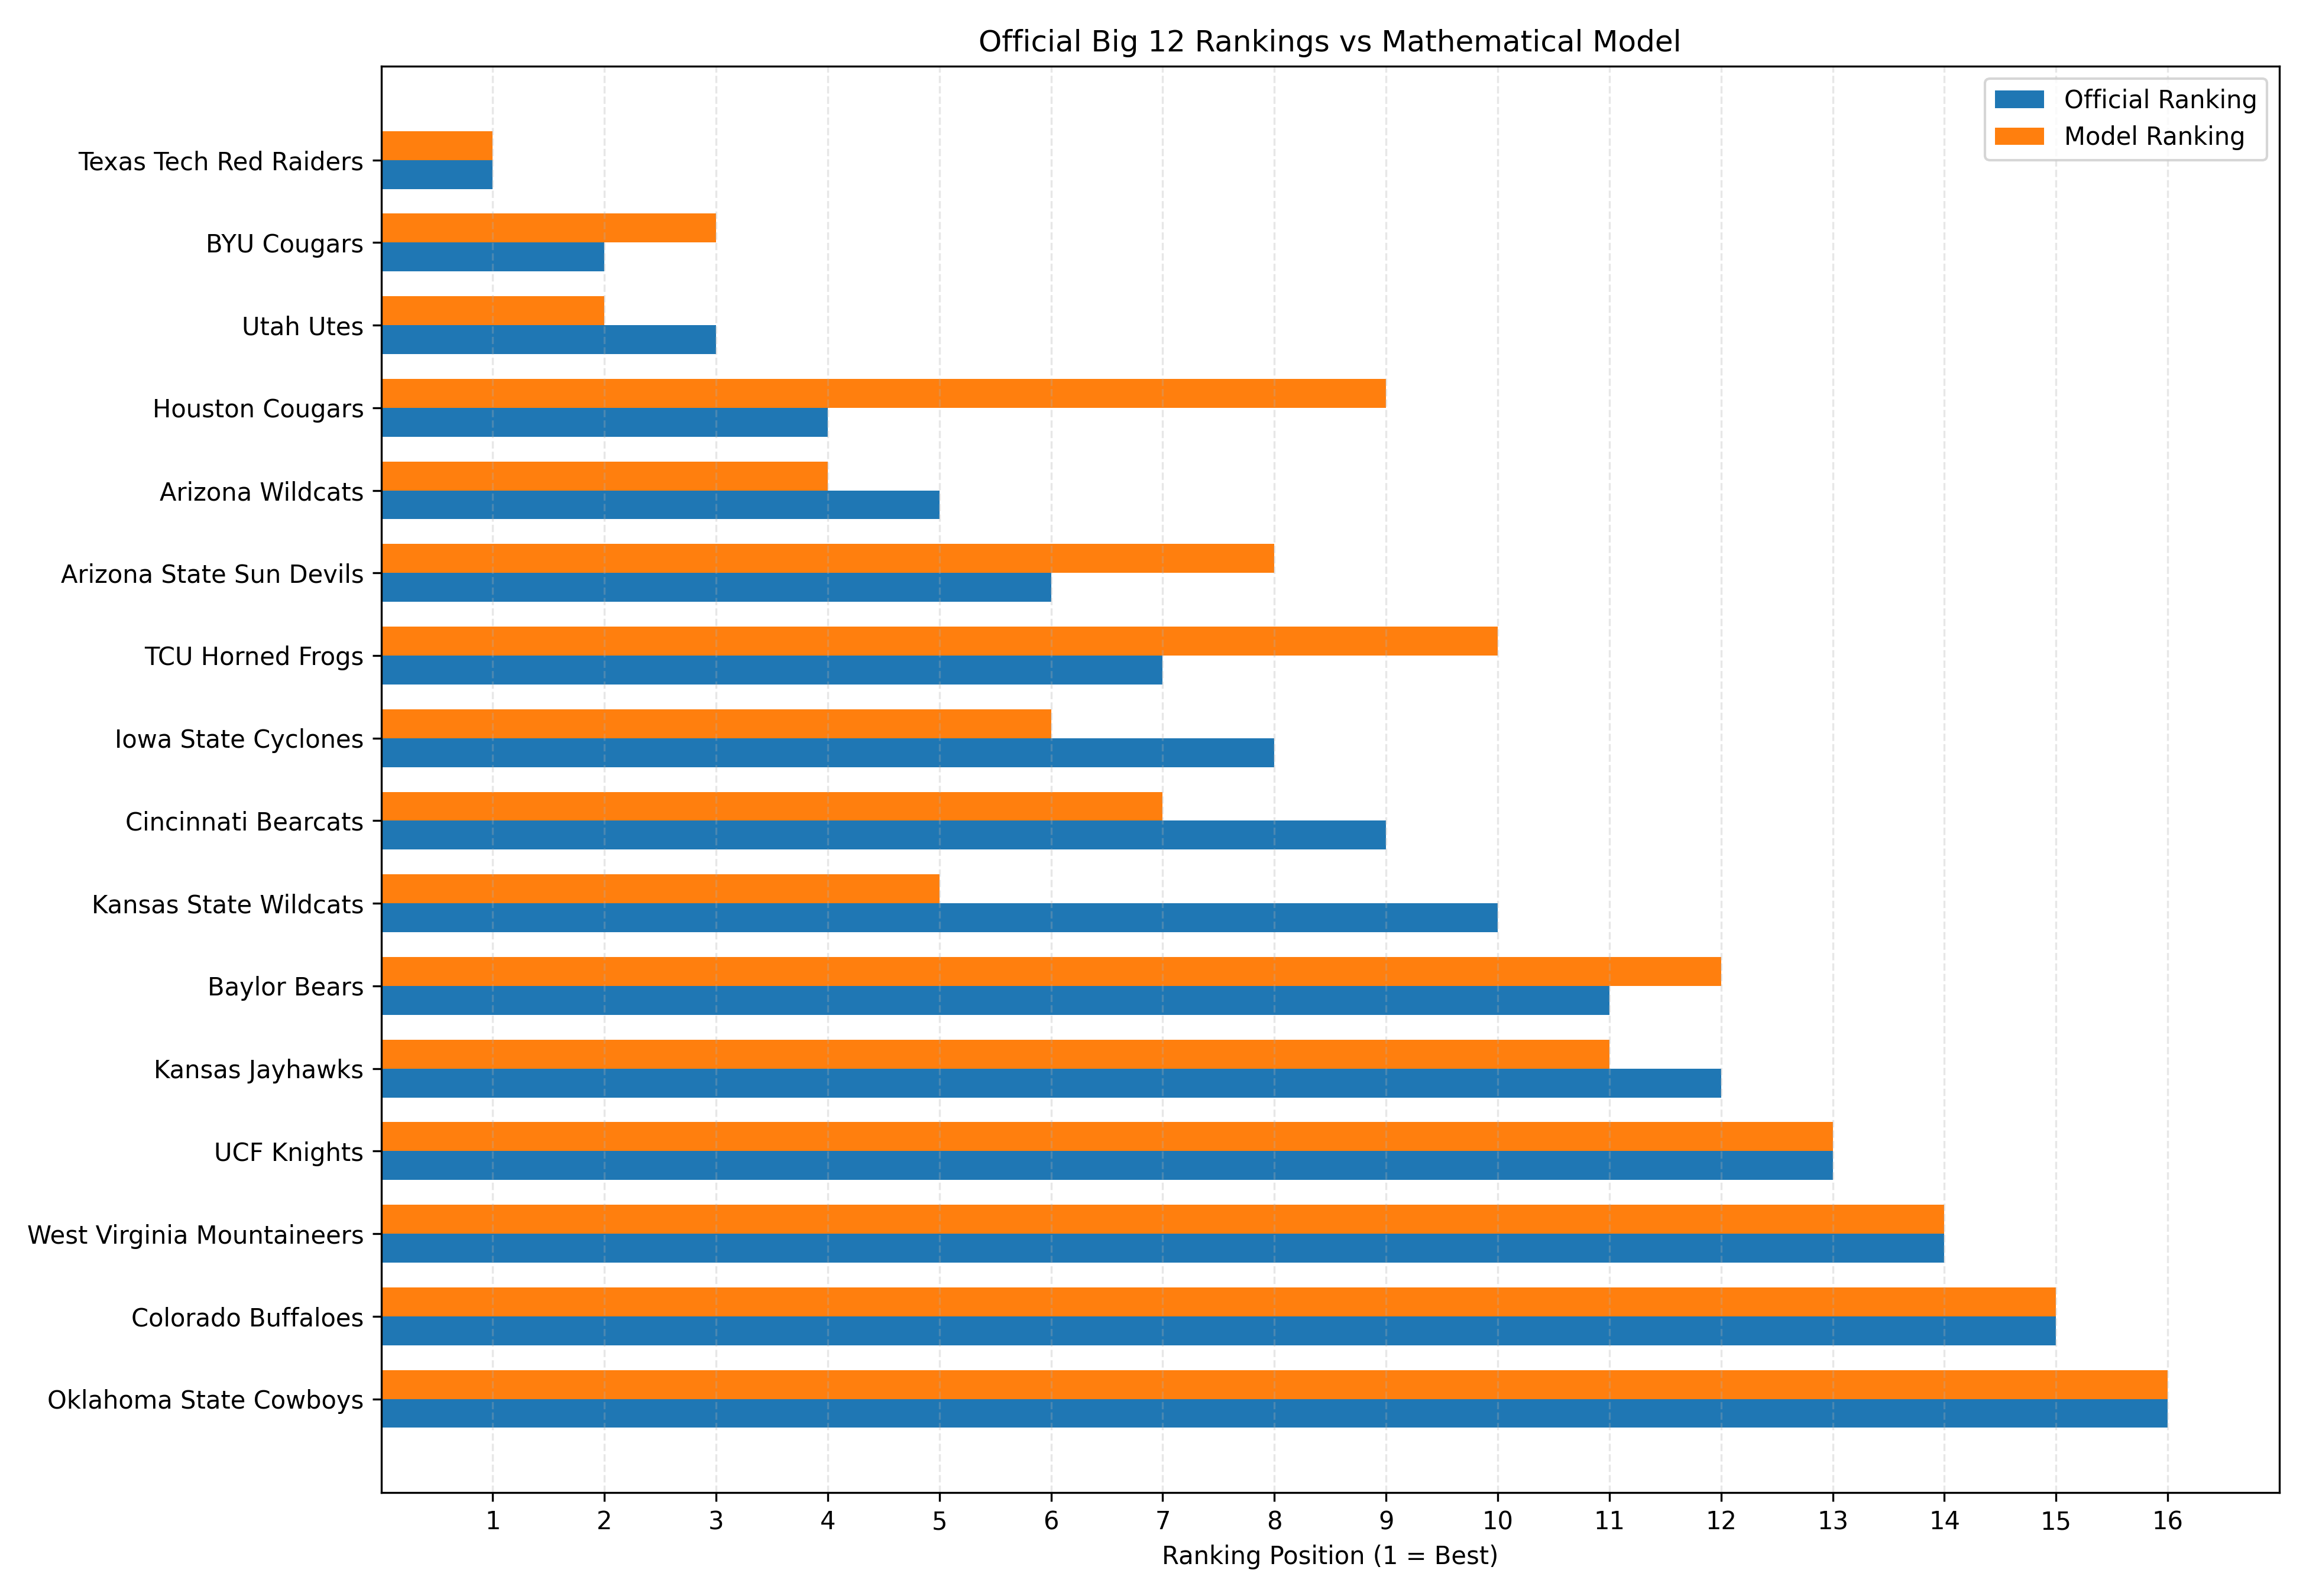

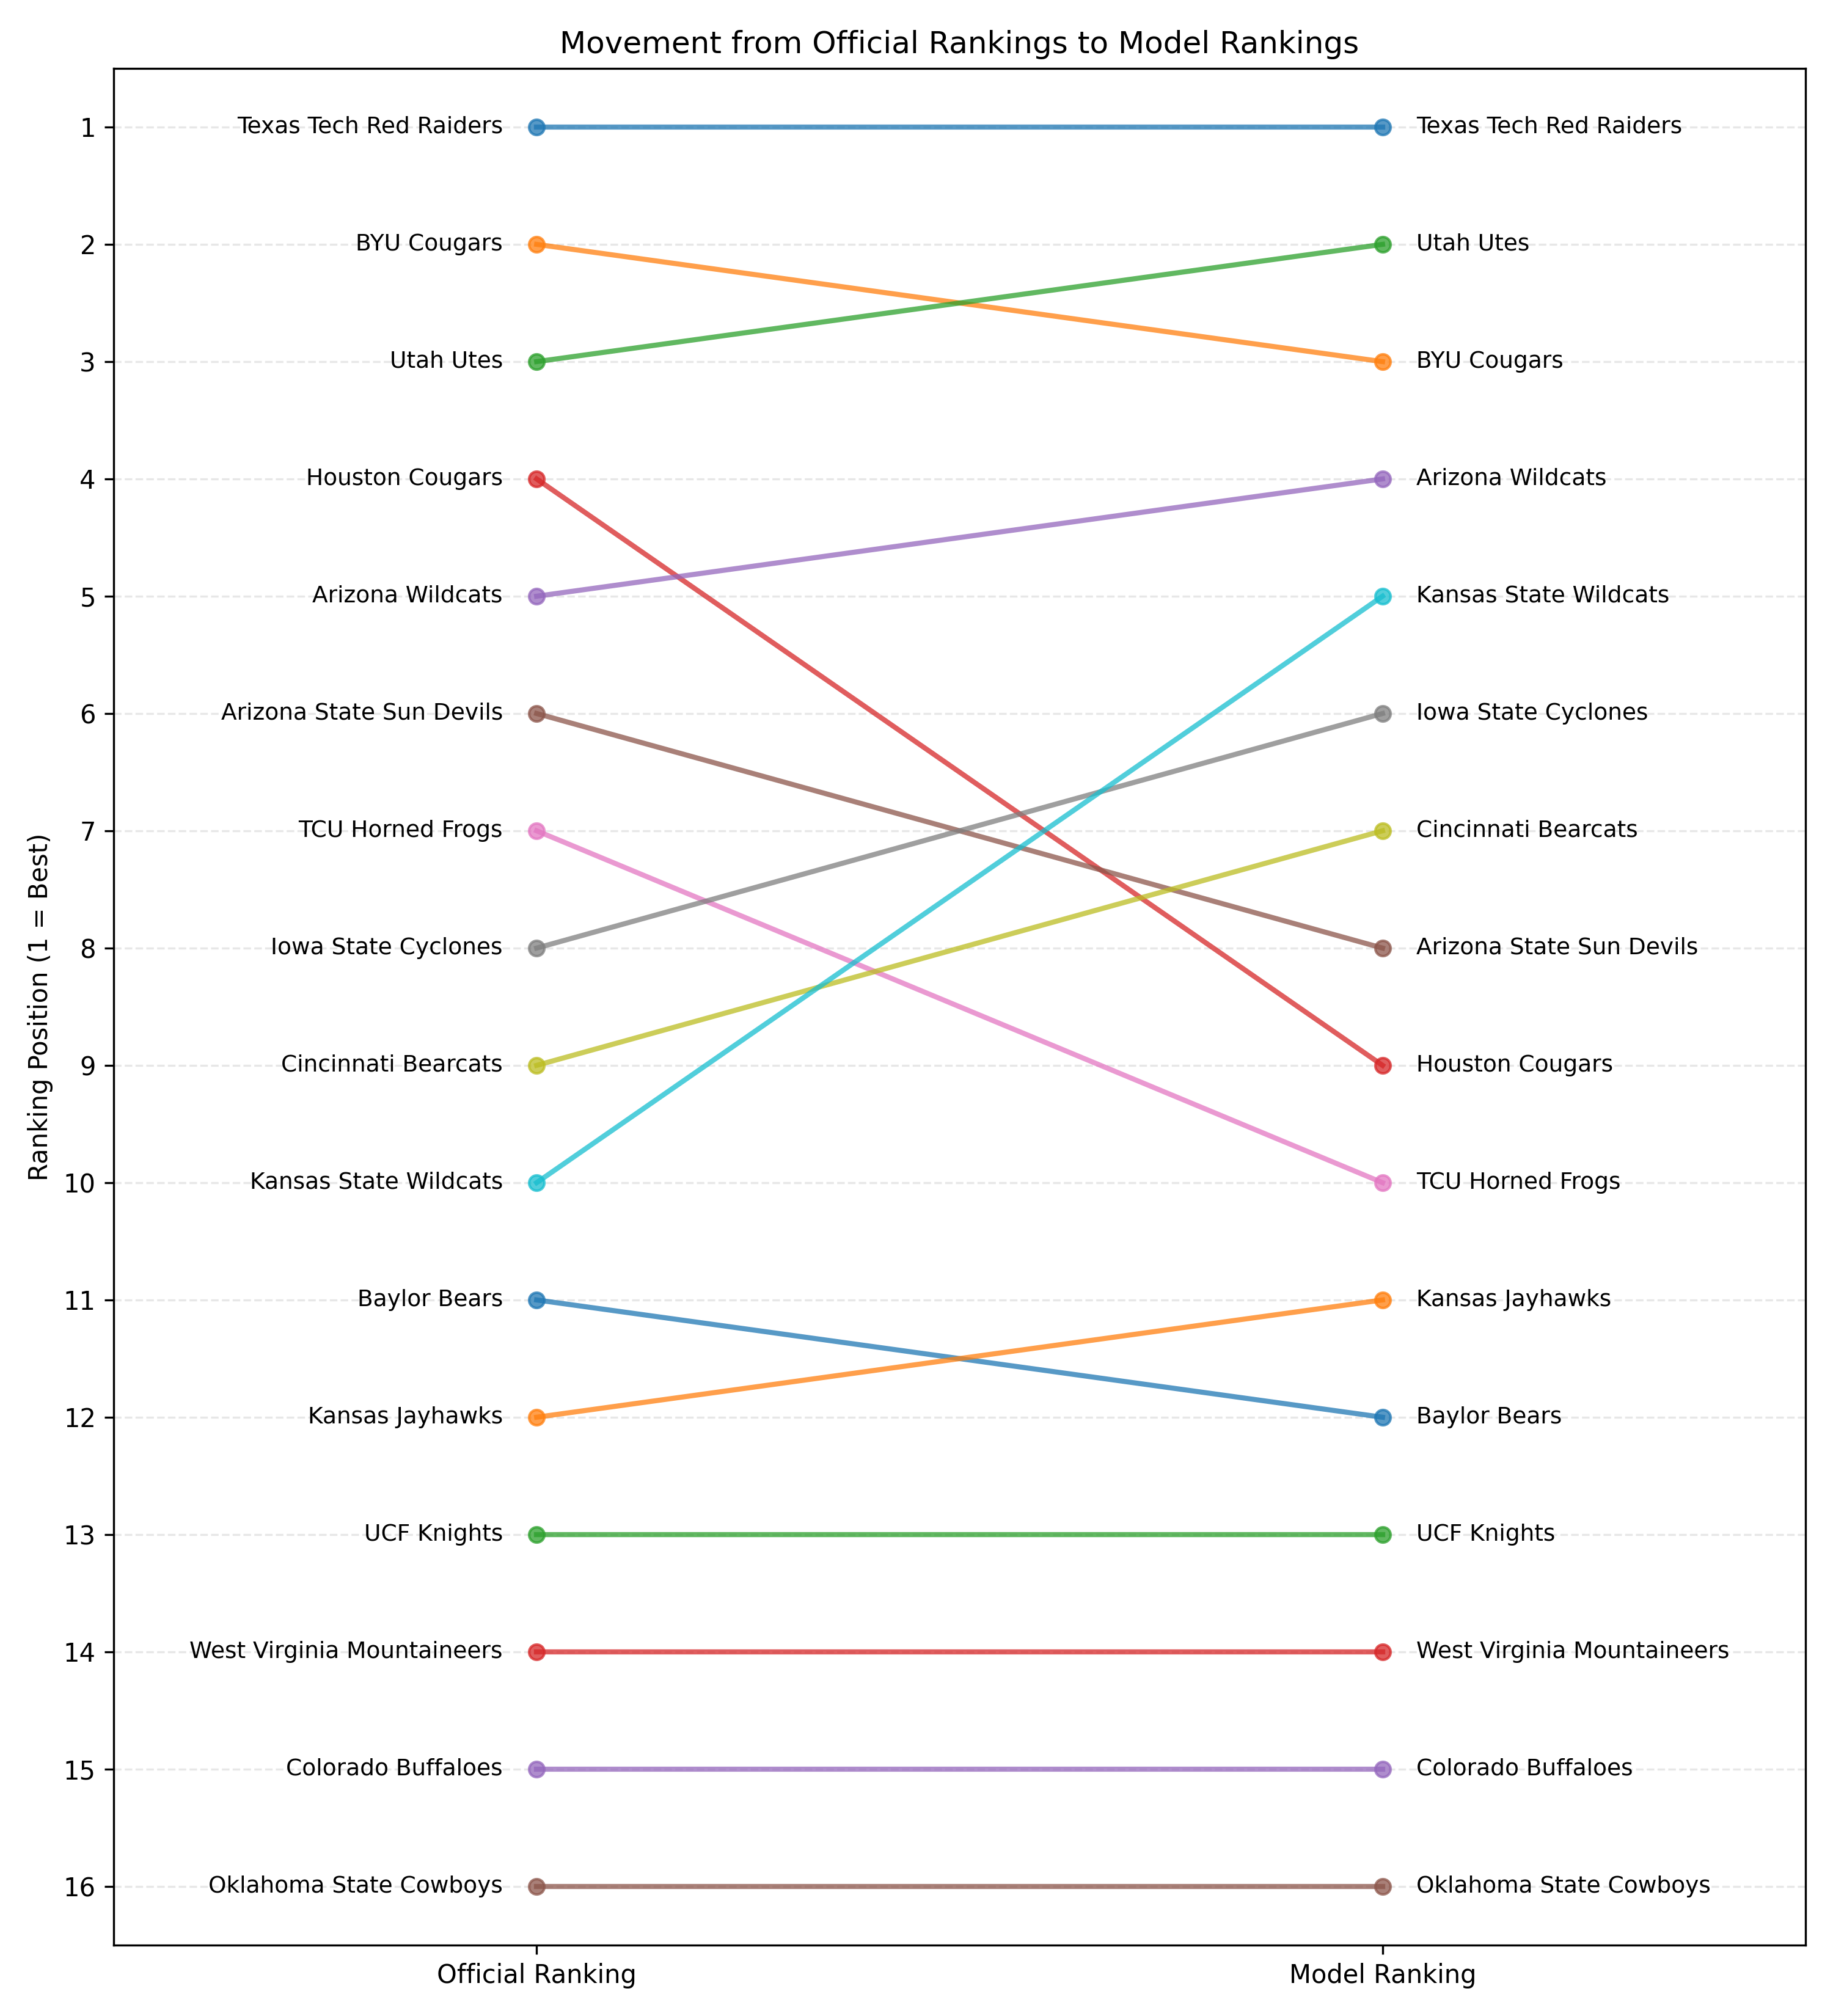

In [13]:
from IPython.display import Image, display

display(Image(filename="../figures/Ranking_Comparison_Bar.png"))

display(Image(filename="../figures/Ranking_Comparison_Slope.png"))

In [30]:
game_comparison = pd.read_csv("results/Game_Residuals.csv")

display(game_comparison)

,Date,Team_A,Score_A,Team_B,Score_B,Real_Gap,Predicted_Gap,Miss_Predicted_minus_Real
0,2025-08-23,Kansas State Wildcats,21.0,Iowa State Cyclones,24.0,-3.0,2.43,5.43
1,2025-09-12,Houston Cougars,36.0,Colorado Buffaloes,20.0,16.0,13.17,-2.83
2,2025-09-20,Utah Utes,10.0,Texas Tech Red Raiders,34.0,-24.0,-7.81,16.19
3,2025-09-20,Kansas Jayhawks,41.0,West Virginia Mountaineers,10.0,31.0,11.48,-19.52
4,2025-09-20,Baylor Bears,24.0,Arizona State Sun Devils,27.0,-3.0,-5.01,-2.01
...,...,...,...,...,...,...,...,...
67,2025-11-29,Oklahoma State Cowboys,13.0,Iowa State Cyclones,20.0,-7.0,-18.88,-11.88
68,2025-11-29,Baylor Bears,24.0,Houston Cougars,31.0,-7.0,-3.99,3.01
69,2025-11-29,Kansas State Wildcats,24.0,Colorado Buffaloes,14.0,10.0,17.83,7.83
70,2025-11-29,BYU Cougars,41.0,UCF Knights,21.0,20.0,19.60,-0.40
